# From Reviews to Insights: Sentiment Analysis of Indonesian Mobile Banking Reviews

This notebook turns the review-level predictions into findings: sentiment by app and month, the Livin' blocking/boycott cluster, and sentiment by app version. It starts from `population_predictions.csv` (every review in the study period, scored by the fold ensemble) and the test-set predictions of the same model.

| Stage | Question |
|---|---|
| 1. Data and integrity | Are the predictions complete and consistent? |
| 2. Classifier error profile | How often does the model confuse the classes, and how uncertain is that estimate? |
| 3. Sentiment by app | What share of reviews is negative, neutral and positive? |
| 4. Sentiment by month | How does it move over the study period? |
| 5. Blocking/boycott cluster | How much of the Livin' August signal is about bank policy rather than the app? |
| 6. App versions | Where are negative reviews concentrated, and does sentiment improve with newer versions? |
| 7. Validity check | Do predicted classes agree with star ratings in the expected way? |
| 8. Export | Tables and figures for the report, plus a list of limitations |

**How to read the numbers**

- *Predicted* shares count the model's hard labels. *Soft* shares average the class probabilities. *Corrected* shares adjust the predicted shares for the classifier's error rates, measured on the held-out test set (matrix-inversion prevalence estimation with a non-negativity constraint).
- Intervals on corrected shares come from resampling the test set by text group, so they reflect classifier uncertainty only. The reviews are a census of the scraped period, not a sample from it.
- The corrected estimates assume the error rates measured on the test set also hold in the population, and that the test labels follow the labeling guidelines of this project.
- Differences between apps or versions are associations. Nothing here identifies a cause.

## 0. Setup

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.optimize import nnls
from scipy.stats import spearmanr
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

In [2]:
SEED = 42
LABEL_NAMES = {0: "negative", 1: "neutral", 2: "positive"}
N_CLASSES = len(LABEL_NAMES)
P_COLS = [f"p_{name}" for name in LABEL_NAMES.values()]

# ---- test-set predictions of the final model
TEST_TAG = "B"
SEEDS = [42, 43, 44]
SELECTED_EPOCH = 4

# ---- estimation
N_BOOT = 1000
MIN_REVIEWS_PER_CELL = 200
MIN_REVIEWS_PER_VERSION = 100
SPIKE_RATIO = 3
GAP_RATIO = 0.25

# ---- Livin' blocking/boycott cluster
BLOCKING_PATTERN = (r"aktivis|aktifis|boikot|sepihak|penegak hukum|botok|aparat|antek|tikus|memblokir|pemblokiran"
                    r"|main blokir|asal blokir|tukang blokir|blokir (?:rekening|dana|tabungan|saldo|uang|nasabah)")

MOUNT_DRIVE = True

In [3]:
IN_COLAB = "google.colab" in sys.modules
BASE_DIR = Path("mbanking_sentiment")
if IN_COLAB and MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/mbanking_sentiment")

PROCESSED_DIR = BASE_DIR / "data" / "processed"
RESULTS_DIR = BASE_DIR / "results"
ANALYSIS_DIR = RESULTS_DIR / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.RandomState(SEED)

Mounted at /content/drive


## 1. Data and Integrity

Every anomaly is collected as a `FLAG`. The check also reports how often the two version columns agree, the share of reviews without a version, and months whose volume is far above or below the app's typical month.

In [4]:
predictions = pd.read_csv(
    PROCESSED_DIR / "population_predictions.csv", encoding="utf-8-sig", parse_dates=["review_date"],
    dtype={"review_created_version": str, "app_version": str})
flags = []

n_duplicates = int(predictions["review_id"].duplicated().sum())
if n_duplicates:
    flags.append(f"{n_duplicates} duplicated review_id rows")
if predictions[P_COLS].isna().any(axis=1).any():
    flags.append("missing class probabilities")
if (predictions[P_COLS].sum(axis=1) - 1).abs().max() > 1e-3:
    flags.append("class probabilities do not sum to one")
mismatch = int((predictions[P_COLS].to_numpy().argmax(axis=1) != predictions["pred_label_id"].to_numpy()).sum())
if mismatch:
    flags.append(f"{mismatch} rows where pred_label_id is not the argmax of the probabilities")
if predictions["review_date"].isna().any():
    flags.append("reviews without a date")

print(f"population: {len(predictions)} reviews | dates {predictions['review_date'].min().date()} to "
      f"{predictions['review_date'].max().date()}")

monthly = predictions.pivot_table(index="review_month", columns="app_name", values="review_id", aggfunc="count")
print("\nReviews per app and month")
print(monthly)
for app_name in monthly.columns:
    typical = monthly[app_name].median()
    for month, count in monthly[app_name].items():
        if count > SPIKE_RATIO * typical:
            flags.append(f"{app_name}: {month} has {count} reviews, {count / typical:.1f}x the monthly median")
        elif count < GAP_RATIO * typical:
            flags.append(f"{app_name}: {month} has only {count} reviews (monthly median {typical:.0f})")

print("\nMissing app version (share within app)")
print(predictions.groupby("app_name")["app_version"].apply(lambda s: s.isna().mean()).round(3))
same_version = (predictions["app_version"].fillna("") == predictions["review_created_version"].fillna("")).mean()
print(f"rows where app_version equals review_created_version: {same_version:.1%}")
if same_version < 0.99:
    flags.append("app_version and review_created_version differ in some rows")

print("\nLow-confidence predictions (max probability < 0.6), share within app")
print(predictions.groupby("app_name")["max_prob"].apply(lambda s: (s < 0.6).mean()).round(4))

print("\nFLAGS")
for flag in flags or ["none"]:
    print(" - " + flag)

population: 134910 reviews | dates 2026-01-01 to 2026-08-31

Reviews per app and month
app_name      BRImo  Livin_by_Mandiri  myBCA  wondr_by_BNI
review_month                                              
2026-01        8046              1456    736          3493
2026-02        7820              1637    657          3486
2026-03        8858              5372   1520          4491
2026-04        9067              2499   1413          3906
2026-05        7713              1767   1462          3659
2026-06        6333              1448    930          3909
2026-07        6495              3326   1179          3810
2026-08        5174             18463    935          3850

Missing app version (share within app)
app_name
BRImo               0.184
Livin_by_Mandiri    0.358
myBCA               0.221
wondr_by_BNI        0.100
Name: app_version, dtype: float64
rows where app_version equals review_created_version: 100.0%

Low-confidence predictions (max probability < 0.6), share within app
app_n

## 2. Classifier Error Profile

The test predictions are the average of the fold models at the selected epoch, the same quantity evaluated in the modelling notebook, so accuracy and macro-F1 printed here should match that evaluation. The confusion matrix is converted to error rates (true class to predicted class) and resampled by text group to carry the uncertainty into all later estimates.

In [5]:
test_set = pd.read_csv(PROCESSED_DIR / "test.csv", encoding="utf-8-sig")
test_stack = np.mean([np.load(RESULTS_DIR / f"test_{TEST_TAG}_s{seed}.npy") for seed in SEEDS], axis=0)
test_probs = test_stack[min(SELECTED_EPOCH, len(test_stack)) - 1]
assert len(test_probs) == len(test_set), "test predictions do not align with test.csv"

y_test = test_set["label_id"].to_numpy()
test_pred = test_probs.argmax(axis=1)
print(f"test accuracy {accuracy_score(y_test, test_pred):.3f} | macro-F1 "
      f"{f1_score(y_test, test_pred, average='macro', labels=list(LABEL_NAMES)):.3f}")

counts = confusion_matrix(y_test, test_pred, labels=list(LABEL_NAMES)).astype(float)
rates = counts / counts.sum(axis=1, keepdims=True)
names = list(LABEL_NAMES.values())
print("\nConfusion matrix (rows true, columns predicted)")
print(pd.DataFrame(counts.astype(int), index=names, columns=names))
print("\nError rates (share of each true class assigned to each predicted class)")
print(pd.DataFrame(rates, index=names, columns=names).round(3))


def bootstrap_rates(y_true, y_pred, groups, n_boot=N_BOOT, seed=SEED):
    generator = np.random.RandomState(seed)
    codes, uniques = pd.factorize(groups)
    members = [np.flatnonzero(codes == code) for code in range(len(uniques))]
    replicates = []
    for _ in range(n_boot):
        picked = generator.randint(0, len(members), len(members))
        index = np.concatenate([members[g] for g in picked])
        table = confusion_matrix(y_true[index], y_pred[index], labels=list(LABEL_NAMES)).astype(float)
        totals = table.sum(axis=1, keepdims=True)
        table = np.where(totals > 0, table / np.maximum(totals, 1), np.eye(N_CLASSES))
        replicates.append(table)
    return np.array(replicates)


rate_boot = bootstrap_rates(y_test, test_pred, test_set["text_key"])
print("\nTest rows per true class:", dict(zip(names, counts.sum(axis=1).astype(int))))
if (counts.sum(axis=1) < 30).any():
    print("FLAG: a class has fewer than 30 test rows, so its error rates and every corrected share are rough")

test accuracy 0.974 | macro-F1 0.944

Confusion matrix (rows true, columns predicted)
          negative  neutral  positive
negative       250        2         2
neutral          3       24         2
positive         4        0       213

Error rates (share of each true class assigned to each predicted class)
          negative  neutral  positive
negative     0.984    0.008     0.008
neutral      0.103    0.828     0.069
positive     0.018    0.000     0.982

Test rows per true class: {'negative': np.int64(254), 'neutral': np.int64(29), 'positive': np.int64(217)}
FLAG: a class has fewer than 30 test rows, so its error rates and every corrected share are rough


## 3. Sentiment by App

`correct_shares` solves `predicted = rates^T x` for the true class shares `x` under non-negativity and a sum-to-one constraint. With a classifier this accurate the correction is small; its size is itself informative about how much the conclusions depend on the model.

Sentiment shares by app
        app_name     n  negative_predicted  negative_corrected  neutral_predicted  neutral_corrected  positive_predicted  positive_corrected
           BRImo 59506               0.303               0.289              0.057              0.066               0.640               0.645
Livin_by_Mandiri 35968               0.701               0.702              0.041              0.043               0.258               0.255
           myBCA  8832               0.646               0.644              0.060              0.066               0.294               0.290
    wondr_by_BNI 30604               0.270               0.253              0.068              0.079               0.663               0.668

Corrected shares with 95% intervals
  BRImo: negative 0.289 [0.245, 0.303] | neutral 0.066 [0.056, 0.137] | positive 0.645 [0.611, 0.661]
  Livin_by_Mandiri: negative 0.702 [0.668, 0.716] | neutral 0.043 [0.031, 0.090] | positive 0.255 [0.233, 0.264]
  myBCA: negative 0

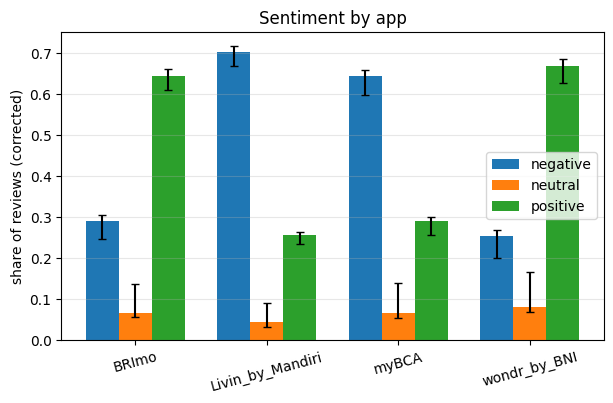

In [6]:
def correct_shares(pred_share, rate_matrix):
    system = np.vstack([rate_matrix.T, 1e3 * np.ones(N_CLASSES)])
    target = np.append(pred_share, 1e3)
    solution, _ = nnls(system, target)
    return solution / solution.sum()


def corrected_with_ci(pred_share):
    point = correct_shares(pred_share, rates)
    replicates = np.array([correct_shares(pred_share, replicate) for replicate in rate_boot])
    return point, np.percentile(replicates, 2.5, axis=0), np.percentile(replicates, 97.5, axis=0)


def share_table(frame, by):
    by = [by] if isinstance(by, str) else list(by)
    rows = []
    for key, group in frame.groupby(by):
        key = key if isinstance(key, tuple) else (key,)
        hard = np.bincount(group["pred_label_id"], minlength=N_CLASSES) / len(group)
        point, low, high = corrected_with_ci(hard)
        row = dict(zip(by, key))
        row["n"] = len(group)
        for index, name in LABEL_NAMES.items():
            row[f"{name}_predicted"] = hard[index]
            row[f"{name}_soft"] = group[P_COLS[index]].mean()
            row[f"{name}_corrected"] = point[index]
            row[f"{name}_ci_low"] = low[index]
            row[f"{name}_ci_high"] = high[index]
        rows.append(row)
    return pd.DataFrame(rows)


app_shares = share_table(predictions, "app_name")
print("Sentiment shares by app")
columns = ["app_name", "n"] + [f"{name}_{kind}" for name in names for kind in ("predicted", "corrected")]
print(app_shares[columns].round(3).to_string(index=False))
print("\nCorrected shares with 95% intervals")
for _, row in app_shares.iterrows():
    parts = [f"{name} {row[f'{name}_corrected']:.3f} [{row[f'{name}_ci_low']:.3f}, {row[f'{name}_ci_high']:.3f}]"
             for name in names]
    print(f"  {row['app_name']}: " + " | ".join(parts))

fig, axis = plt.subplots(figsize=(7, 4))
width = 0.25
positions = np.arange(len(app_shares))
for offset, name in enumerate(names):
    values = app_shares[f"{name}_corrected"].to_numpy()
    errors = np.vstack([values - app_shares[f"{name}_ci_low"], app_shares[f"{name}_ci_high"] - values])
    axis.bar(positions + (offset - 1) * width, values, width, yerr=errors, capsize=3, label=name)
axis.set_xticks(positions)
axis.set_xticklabels(app_shares["app_name"], rotation=15)
axis.set_ylabel("share of reviews (corrected)")
axis.set_title("Sentiment by app")
axis.legend()
axis.grid(axis="y", alpha=0.3)
fig.savefig(ANALYSIS_DIR / "sentiment_by_app.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Sentiment by Month

Cells below `MIN_REVIEWS_PER_CELL` are marked, because their predicted shares move a lot with a handful of reviews. The Livin' series is read together with Stage 5, since its August level is affected by a topic that is not about the app.


Corrected negative share by app and month
app_name      BRImo  Livin_by_Mandiri  myBCA  wondr_by_BNI
review_month                                              
2026-01       0.347             0.667  0.547         0.197
2026-02       0.294             0.550  0.554         0.237
2026-03       0.208             0.375  0.720         0.257
2026-04       0.270             0.626  0.692         0.321
2026-05       0.288             0.568  0.641         0.248
2026-06       0.341             0.561  0.716         0.224
2026-07       0.305             0.314  0.585         0.241
2026-08       0.285             0.918  0.593         0.291

Corrected positive share by app and month
app_name      BRImo  Livin_by_Mandiri  myBCA  wondr_by_BNI
review_month                                              
2026-01       0.597             0.278  0.362         0.716
2026-02       0.643             0.384  0.370         0.684
2026-03       0.712             0.550  0.224         0.666
2026-04       0.659          

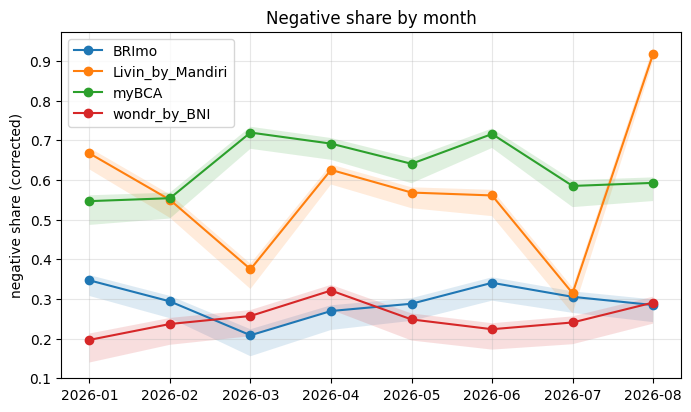

In [7]:
month_shares = share_table(predictions, ["app_name", "review_month"])
month_shares["thin_cell"] = month_shares["n"] < MIN_REVIEWS_PER_CELL
if month_shares["thin_cell"].any():
    print("FLAG: cells with fewer than", MIN_REVIEWS_PER_CELL, "reviews")
    print(month_shares.loc[month_shares["thin_cell"], ["app_name", "review_month", "n"]].to_string(index=False))

print("\nCorrected negative share by app and month")
print(month_shares.pivot(index="review_month", columns="app_name", values="negative_corrected").round(3))
print("\nCorrected positive share by app and month")
print(month_shares.pivot(index="review_month", columns="app_name", values="positive_corrected").round(3))

fig, axis = plt.subplots(figsize=(8, 4.5))
for app_name, group in month_shares.groupby("app_name"):
    axis.plot(group["review_month"], group["negative_corrected"], marker="o", label=app_name)
    axis.fill_between(group["review_month"], group["negative_ci_low"], group["negative_ci_high"], alpha=0.15)
axis.set_ylabel("negative share (corrected)")
axis.set_title("Negative share by month")
axis.legend()
axis.grid(alpha=0.3)
fig.savefig(ANALYSIS_DIR / "negative_share_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Blocking/Boycott Cluster

Some reviews, concentrated in one month and one app, criticize a bank policy (account blocking, protest against the bank) instead of the app. They are labeled by the sentiment they express, so they are mostly negative, but they say little about app quality. The cluster is flagged with a keyword pattern. A keyword pattern is imprecise in both directions, so the cell prints random matches and random non-matches for a manual check before any number is used, and the analysis is reported with and without the flagged reviews.

In [8]:
predictions["blocking_topic"] = predictions["text_norm"].str.lower().str.contains(BLOCKING_PATTERN, regex=True)

cluster_by_cell = predictions.pivot_table(index="review_month", columns="app_name", values="blocking_topic", aggfunc="mean")
print("Share of reviews flagged as blocking/boycott topic")
print(cluster_by_cell.round(3))
print("\nFlagged reviews per app:", predictions.groupby("app_name")["blocking_topic"].sum().astype(int).to_dict())

flagged = predictions[predictions["blocking_topic"]]
print(f"\nShare of flagged reviews predicted negative: {(flagged['pred_label_id'] == 0).mean():.3f}")
print("\nRandom flagged reviews (precision check)")
for text in flagged.sample(min(15, len(flagged)), random_state=SEED)["text_raw"]:
    print("  -", text[:130].replace("\n", " "))
print("\nRandom unflagged reviews mentioning 'blokir' (recall check)")
leftover = predictions[~predictions["blocking_topic"] & predictions["text_norm"].str.lower().str.contains("blokir")]
for text in leftover.sample(min(15, len(leftover)), random_state=SEED)["text_raw"]:
    print("  -", text[:130].replace("\n", " "))

Share of reviews flagged as blocking/boycott topic
app_name      BRImo  Livin_by_Mandiri  myBCA  wondr_by_BNI
review_month                                              
2026-01       0.000             0.000  0.001         0.000
2026-02       0.000             0.001  0.002         0.000
2026-03       0.000             0.001  0.001         0.000
2026-04       0.001             0.002  0.001         0.001
2026-05       0.000             0.001  0.001         0.001
2026-06       0.000             0.001  0.001         0.001
2026-07       0.000             0.001  0.002         0.000
2026-08       0.001             0.281  0.005         0.001

Flagged reviews per app: {'BRImo': 22, 'Livin_by_Mandiri': 5214, 'myBCA': 14, 'wondr_by_BNI': 14}

Share of flagged reviews predicted negative: 0.992

Random flagged reviews (precision check)
  - ATM orang main blokir,kasih bintang 1 biar investasi asing pada lihat kelakuan bank mandiri
  - pemblokir nasabah aktifis!!
  - Mandiri lah Dalam Kemandirian mu B

In [9]:
without_cluster = predictions[~predictions["blocking_topic"]]
with_all = month_shares[["app_name", "review_month", "n", "negative_corrected"]].rename(
    columns={"n": "n_all", "negative_corrected": "negative_all"})
without = share_table(without_cluster, ["app_name", "review_month"])[["app_name", "review_month", "n", "negative_corrected"]]
without = without.rename(columns={"n": "n_without", "negative_corrected": "negative_without"})
comparison = with_all.merge(without, on=["app_name", "review_month"])
comparison["difference"] = comparison["negative_all"] - comparison["negative_without"]

print("Negative share (corrected) with and without the flagged reviews, largest differences")
print(comparison.sort_values("difference", ascending=False).head(10).round(3).to_string(index=False))

app_without = share_table(without_cluster, "app_name")
print("\nNegative share by app, all reviews versus without the flagged reviews")
print(pd.DataFrame({
    "all": app_shares.set_index("app_name")["negative_corrected"],
    "without_cluster": app_without.set_index("app_name")["negative_corrected"],
}).assign(difference=lambda frame: frame["all"] - frame["without_cluster"]).round(3))

Negative share (corrected) with and without the flagged reviews, largest differences
        app_name review_month  n_all  negative_all  n_without  negative_without  difference
Livin_by_Mandiri      2026-08  18463         0.918      13266             0.883       0.035
           myBCA      2026-08    935         0.593        930             0.592       0.001
           BRImo      2026-08   5174         0.285       5167             0.284       0.001
    wondr_by_BNI      2026-05   3659         0.248       3655             0.247       0.001
Livin_by_Mandiri      2026-04   2499         0.626       2494             0.625       0.001
           myBCA      2026-07   1179         0.585       1177             0.584       0.001
           myBCA      2026-02    657         0.554        656             0.553       0.001
           myBCA      2026-01    736         0.547        735             0.546       0.001
Livin_by_Mandiri      2026-07   3326         0.314       3323             0.314       0

## 6. App Versions

Version analysis has three weaknesses that the output makes visible: many reviews have no version, a version's reviews span a long time because users update at different speeds, and version and calendar time are strongly correlated. Versions with fewer than `MIN_REVIEWS_PER_VERSION` reviews are drawn only in the table. The trend test is a logistic regression of "predicted negative" on version order with month fixed effects, which compares versions while holding the calendar month constant; the correlation between version order and month is printed because a very high value means the two cannot be separated well.

In [10]:
def version_key(text):
    parts = re.findall(r"\d+", str(text))
    return tuple(int(part) for part in parts) if parts else None


def wilson(successes, total, z=1.96):
    share = successes / total
    center = (share + z ** 2 / (2 * total)) / (1 + z ** 2 / total)
    spread = z * np.sqrt(share * (1 - share) / total + z ** 2 / (4 * total ** 2)) / (1 + z ** 2 / total)
    return center - spread, center + spread


versions = predictions[predictions["app_version"].notna()].copy()
versions["version_key"] = versions["app_version"].map(version_key)
versions = versions[versions["version_key"].notna()].copy()
versions["negative"] = (versions["pred_label_id"] == 0).astype(int)
rank_maps = {app_name: {key: position for position, key in enumerate(sorted(set(keys)))}
             for app_name, keys in versions.groupby("app_name")["version_key"]}
versions["version_rank"] = [rank_maps[app_name][key] for app_name, key in zip(versions["app_name"], versions["version_key"])]
versions["month_index"] = versions["review_month"].rank(method="dense").astype(int)

rows = []
for (app_name, version), group in versions.groupby(["app_name", "app_version"]):
    low, high = wilson(int(group["negative"].sum()), len(group))
    rows.append({
        "app_name": app_name, "app_version": version, "version_key": group["version_key"].iloc[0], "n": len(group),
        "first_date": group["review_date"].min().date(), "last_date": group["review_date"].max().date(),
        "negative_share": group["negative"].mean(), "ci_low": low, "ci_high": high,
        "soft_negative": group["p_negative"].mean(),
    })
version_table = pd.DataFrame(rows).sort_values(["app_name", "version_key"]).reset_index(drop=True)
version_table["reliable"] = version_table["n"] >= MIN_REVIEWS_PER_VERSION

print("Versions per app (all / with at least", MIN_REVIEWS_PER_VERSION, "reviews)")
print(version_table.groupby("app_name").agg(versions=("app_version", "size"), reliable=("reliable", "sum")))
covered = versions.merge(version_table[["app_name", "app_version", "reliable"]], on=["app_name", "app_version"])
print("\nShare of versioned reviews that sit in reliable versions:", round(covered["reliable"].mean(), 3))
print("Share of all reviews with a usable version, by app:")
print(predictions["review_id"].isin(versions["review_id"]).groupby(predictions["app_name"]).mean().round(3))

print("\nVersion table (reliable versions)")
print(version_table.loc[version_table["reliable"], ["app_name", "app_version", "n", "first_date", "last_date",
                                                   "negative_share", "ci_low", "ci_high"]].round(3).to_string(index=False))

Versions per app (all / with at least 100 reviews)
                  versions  reliable
app_name                            
BRImo                  107        16
Livin_by_Mandiri        28        11
myBCA                   59        11
wondr_by_BNI            15         4

Share of versioned reviews that sit in reliable versions: 0.981
Share of all reviews with a usable version, by app:
app_name
BRImo               0.816
Livin_by_Mandiri    0.642
myBCA               0.779
wondr_by_BNI        0.900
Name: review_id, dtype: float64

Version table (reliable versions)
        app_name app_version     n first_date  last_date  negative_share  ci_low  ci_high
           BRImo      2.87.1   354 2026-01-01 2026-08-24           0.384   0.335    0.436
           BRImo      2.88.1   110 2026-01-01 2026-08-21           0.391   0.305    0.484
           BRImo      2.89.0   113 2026-01-01 2026-08-19           0.283   0.208    0.372
           BRImo      2.90.0   139 2026-01-01 2026-08-31           0.3

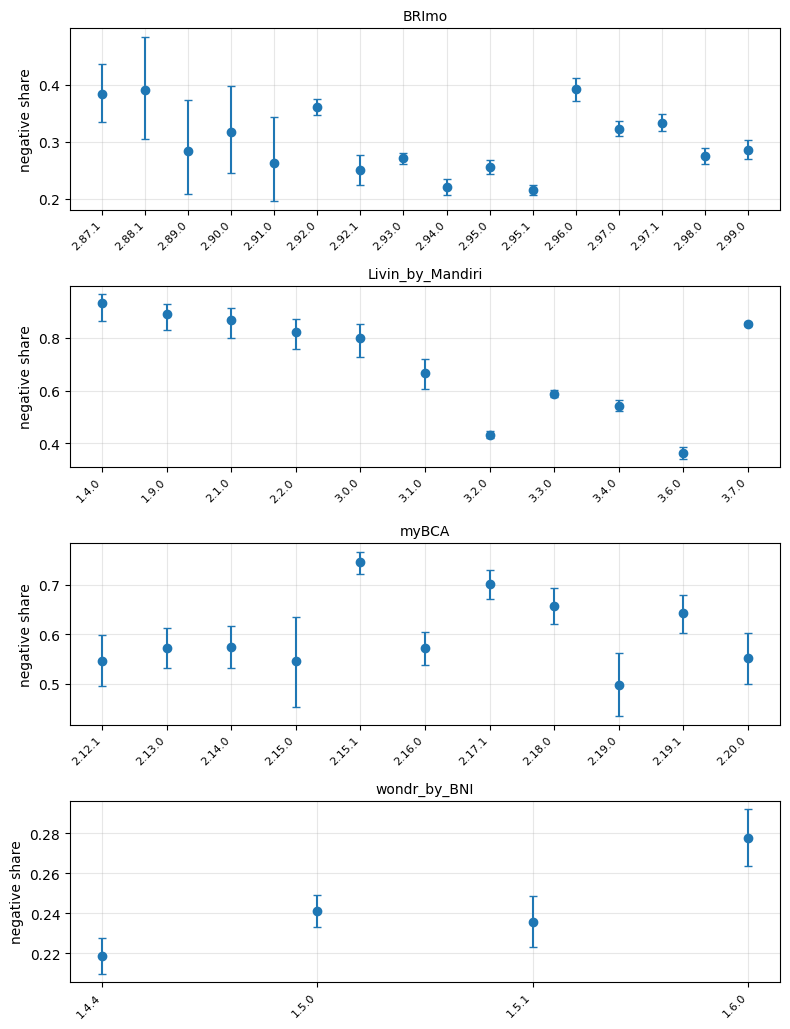

Trend in negative share across successive versions (odds ratio per version step, month fixed effects)
        app_name                         subset  reviews  versions  corr_version_month  odds_ratio_per_version  or_ci_low  or_ci_high
           BRImo          all versioned reviews    48586       107               0.466                   0.972      0.969       0.976
           BRImo         reliable versions only    47783        16               0.906                   0.975      0.961       0.990
           BRImo without blocking/boycott topic    48569       107               0.466                   0.972      0.969       0.976
Livin_by_Mandiri          all versioned reviews    23107        28               0.232                   0.987      0.976       0.999
Livin_by_Mandiri         reliable versions only    22304        11               0.542                   1.028      1.009       1.047
Livin_by_Mandiri without blocking/boycott topic    20553        28               0.268        

In [11]:
reliable_versions = version_table[version_table["reliable"]]
apps = sorted(reliable_versions["app_name"].unique())
fig, axes = plt.subplots(len(apps), 1, figsize=(8, 2.6 * len(apps)), squeeze=False)
for axis, app_name in zip(axes[:, 0], apps):
    group = reliable_versions[reliable_versions["app_name"] == app_name]
    positions = np.arange(len(group))
    values = group["negative_share"].to_numpy()
    errors = np.vstack([values - group["ci_low"], group["ci_high"] - values])
    axis.errorbar(positions, values, yerr=errors, fmt="o", capsize=3)
    axis.set_xticks(positions)
    axis.set_xticklabels(group["app_version"], rotation=45, ha="right", fontsize=8)
    axis.set_title(app_name, fontsize=10)
    axis.set_ylabel("negative share")
    axis.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "negative_share_by_version.png", dpi=150, bbox_inches="tight")
plt.show()


def trend_for(frame, label):
    result = {"subset": label, "reviews": len(frame), "versions": frame["version_rank"].nunique()}
    if frame["version_rank"].nunique() < 3 or frame["review_month"].nunique() < 2:
        return {**result, "note": "too few versions or months"}
    result["corr_version_month"] = float(np.corrcoef(frame["month_index"], frame["version_rank"])[0, 1])
    try:
        model = smf.logit("negative ~ C(review_month) + version_rank", data=frame).fit(disp=0, maxiter=200)
        low, high = model.conf_int().loc["version_rank"]
        result.update({"odds_ratio_per_version": float(np.exp(model.params["version_rank"])),
                       "or_ci_low": float(np.exp(low)), "or_ci_high": float(np.exp(high))})
    except Exception as exc:
        result["note"] = f"model failed: {type(exc).__name__}"
    return result


trend_rows = []
for app_name in apps:
    app_versions = versions[versions["app_name"] == app_name]
    trend_rows.append({"app_name": app_name, **trend_for(app_versions, "all versioned reviews")})
    reliable_keys = set(reliable_versions.loc[reliable_versions["app_name"] == app_name, "app_version"])
    trend_rows.append({"app_name": app_name, **trend_for(
        app_versions[app_versions["app_version"].isin(reliable_keys)], "reliable versions only")})
    trend_rows.append({"app_name": app_name, **trend_for(
        app_versions[~app_versions["blocking_topic"]], "without blocking/boycott topic")})
version_trend = pd.DataFrame(trend_rows)

print("Trend in negative share across successive versions (odds ratio per version step, month fixed effects)")
print(version_trend.round(3).to_string(index=False))
for _, row in version_trend[version_trend["subset"] == "all versioned reviews"].iterrows():
    if abs(row.get("corr_version_month", 0)) > 0.9:
        print(f"FLAG: {row['app_name']}: version order and month are almost collinear "
              f"(r = {row['corr_version_month']:.2f}), the trend cannot be separated from calendar time")

print("\nSpearman correlation between version order and negative share across reliable versions")
for app_name in apps:
    group = reliable_versions[reliable_versions["app_name"] == app_name]
    if len(group) >= 4:
        statistic, p_value = spearmanr(np.arange(len(group)), group["negative_share"])
        print(f"  {app_name}: rho = {statistic:.2f} over {len(group)} versions (p = {p_value:.3f})")
    else:
        print(f"  {app_name}: fewer than 4 reliable versions")

## 7. Validity Check

Star ratings were never used by the model or the labels. If the predictions capture sentiment, the average rating should fall from positive to negative predictions. Reviews that praise the app and still carry a low rating (or the reverse) are expected, as are protest reviews with a deliberately chosen rating.

In [12]:
print("Mean star rating by predicted class")
print(predictions.groupby("pred_label")["rating"].mean().round(2))
print("\nDistribution of star ratings within each predicted class")
print(pd.crosstab(predictions["pred_label"], predictions["rating"], normalize="index").round(3))

mismatch_share = pd.DataFrame({
    "negative_with_5_stars": predictions[predictions["pred_label_id"] == 0].groupby("app_name")["rating"]
                                        .apply(lambda s: (s == 5).mean()),
    "positive_with_1_2_stars": predictions[predictions["pred_label_id"] == 2].groupby("app_name")["rating"]
                                        .apply(lambda s: s.isin([1, 2]).mean()),
})
print("\nRating-sentiment discordance by app")
print(mismatch_share.round(3))

Mean star rating by predicted class
pred_label
negative    1.86
neutral     4.56
positive    4.87
Name: rating, dtype: float64

Distribution of star ratings within each predicted class
rating          1      2      3      4      5
pred_label                                   
negative    0.666  0.087  0.082  0.050  0.114
neutral     0.068  0.010  0.029  0.083  0.809
positive    0.015  0.002  0.007  0.050  0.926

Rating-sentiment discordance by app
                  negative_with_5_stars  positive_with_1_2_stars
app_name                                                        
BRImo                             0.187                    0.005
Livin_by_Mandiri                  0.057                    0.082
myBCA                             0.086                    0.010
wondr_by_BNI                      0.152                    0.010


## 8. Export and Limitations

In [13]:
app_shares.to_csv(ANALYSIS_DIR / "sentiment_by_app.csv", index=False)
month_shares.to_csv(ANALYSIS_DIR / "sentiment_by_app_month.csv", index=False)
comparison.to_csv(ANALYSIS_DIR / "blocking_topic_comparison.csv", index=False)
version_table.drop(columns="version_key").to_csv(ANALYSIS_DIR / "version_table.csv", index=False)
version_trend.to_csv(ANALYSIS_DIR / "version_trend.csv", index=False)
print("saved to", ANALYSIS_DIR)
print(sorted(path.name for path in ANALYSIS_DIR.iterdir()))

saved to /content/drive/MyDrive/mbanking_sentiment/results/analysis
['blocking_topic_comparison.csv', 'negative_share_by_month.png', 'negative_share_by_version.png', 'sentiment_by_app.csv', 'sentiment_by_app.png', 'sentiment_by_app_month.csv', 'version_table.csv', 'version_trend.csv']


### Limitations to state with the results

- **Classifier error.** On the held-out test set the model is accurate for clear negative and positive reviews, and weakest on the neutral class, which has few test rows. Corrected shares and their intervals inherit that uncertainty; the neutral share is the least reliable.
- **Label definition.** Classes follow the labeling guidelines of this project, including conventions for mixed reviews and requests. Another reasonable convention would move some reviews between classes.
- **Test-set representativeness.** The error rates used for correction come from one test sample (500 reviews). They are assumed to transfer to the population and to all apps and months.
- **Review dates.** Google Play may display the date of the latest edit, so the date is not always the date of the experience.
- **App versions.** Many reviews carry no version, and a version's reviews are spread over a long period, so version effects are mixed with calendar effects.
- **Self-selected reviewers.** Reviewers are not a random sample of users; extreme experiences and organized campaigns are over-represented.
- **Topic cluster.** The blocking/boycott cluster is identified by keywords and is therefore approximate.
- **Association only.** None of the comparisons between apps or versions identifies a cause.

In [16]:
five_star_negative = predictions[(predictions["pred_label_id"] == 0) & (predictions["rating"] == 5)]
low_star_positive = predictions[(predictions["pred_label_id"] == 2) & (predictions["rating"] <= 2)]
for name, frame in (("negative with 5 stars", five_star_negative), ("positive with 1-2 stars", low_star_positive)):
    print(f"\n{name}: {len(frame)} reviews")
    for text in frame.sample(20, random_state=SEED)["text_raw"]:
        print("  -", text[:120].replace("\n", " "))


negative with 5 stars: 6548 reviews
  - mengapa aplikasi nya ga bisa masuk
  - kenapa aplikasi BCA makin ke sini makin lemot siii???? ini masalah bangat, apa tidak ada perbaikannya ini min? syaa juga
  - bagus banget ni livin gw kemarin kasih review 1 karena emg gak bisa jalan sekarang bisa gw naikin lagi 5 nice
  - kenapa ketika ganti akun ke hp baru harus verif dan ketika dimasukan no nik yang sesuai tidak bisa melanjutkan
  - min saya udah masukin semua data yang sesuai dngn perintah tapi saya tidak bisa menambahkan pin ... tulisannya terjadi k
  - dsri padacari atm musim hujan
  - Aneh bener, ketika masuk manual menggunakan email, tanda titik tidak bisa/alias tidak terketik di box username, susah la
  - ini kenapa sya tidak bisa login lgi di akun brimo sya di karenakan selalu gagal pripikasi waja.tolong pada pihak BRI aga
  - Fitur nya ngebantu bangett, tapi kenapa sehabis di update jadi susah di bukaa yaa😔🙏🏻
  - terlalu eeput
  - kenapa dua hari ini aplikasi ga bisa di buka ya??


In [17]:
PROMO_PATTERN = r"undian|hadiah|giveaway|doorprize|pemenang|\bmobil\b"
predictions["promo_topic"] = predictions["text_norm"].str.lower().str.contains(PROMO_PATTERN, regex=True)
print(predictions.pivot_table(index="review_month", columns="app_name", values="promo_topic", aggfunc="mean").round(3))

app_name      BRImo  Livin_by_Mandiri  myBCA  wondr_by_BNI
review_month                                              
2026-01       0.001             0.000  0.003         0.001
2026-02       0.001             0.001  0.003         0.003
2026-03       0.000             0.001  0.001         0.002
2026-04       0.000             0.000  0.000         0.002
2026-05       0.000             0.002  0.001         0.001
2026-06       0.000             0.003  0.000         0.001
2026-07       0.001             0.001  0.002         0.001
2026-08       0.001             0.000  0.001         0.002


In [18]:
predictions["has_version"] = predictions["app_version"].notna()
print(predictions.groupby(["app_name", "has_version"])["pred_label_id"].apply(lambda s: (s == 0).mean()).unstack().round(3))

has_version       False  True 
app_name                      
BRImo             0.372  0.288
Livin_by_Mandiri  0.802  0.644
myBCA             0.676  0.637
wondr_by_BNI      0.536  0.240


In [19]:
emoji_only = predictions[predictions["text_norm"].str.contains("[\U0001F000-\U0001FAFF\u2600-\u27BF]")
                         & ~predictions["text_norm"].str.contains(r"[^\W_]")]
print(len(emoji_only), f"{len(emoji_only) / len(predictions):.2%}")
print(emoji_only.assign(thumb_down=emoji_only["text_norm"].str.contains("👎"))
      .groupby("thumb_down")["pred_label"].value_counts(normalize=True).round(3))

1137 0.84%
thumb_down  pred_label
False       positive      1.0
True        positive      1.0
Name: proportion, dtype: float64


In [20]:
predictions["has_version"] = predictions["app_version"].notna()
print(predictions.pivot_table(index="review_month", columns="app_name", values="has_version", aggfunc="mean").round(2))

app_name      BRImo  Livin_by_Mandiri  myBCA  wondr_by_BNI
review_month                                              
2026-01        0.82              0.76   0.77          0.91
2026-02        0.80              0.77   0.78          0.91
2026-03        0.81              0.81   0.77          0.91
2026-04        0.83              0.78   0.79          0.87
2026-05        0.82              0.75   0.80          0.91
2026-06        0.82              0.76   0.75          0.91
2026-07        0.82              0.81   0.77          0.90
2026-08        0.81              0.51   0.79          0.87


In [22]:
livin_negative = predictions[(predictions["app_name"] == "Livin_by_Mandiri") & (predictions["pred_label_id"] == 0)]
august = livin_negative[livin_negative["review_month"] == "2026-08"].sample(300, random_state=SEED).assign(period="2026-08")
earlier = livin_negative[livin_negative["review_month"] < "2026-08"].sample(100, random_state=SEED).assign(period="2026-01..07")
topic_sample = pd.concat([august, earlier]).sample(frac=1, random_state=SEED).reset_index(drop=True)
topic_sample.insert(0, "sample_id", [f"L{i + 1:04d}" for i in range(len(topic_sample))])
topic_sample[["sample_id", "text_raw"]].assign(topic="").to_csv(ANALYSIS_DIR / "topic_sheet_livin.csv", index=False, encoding="utf-8-sig")
topic_sample[["sample_id", "review_id", "period"]].to_csv(ANALYSIS_DIR / "topic_sample_key.csv", index=False)

In [24]:
labeled_topics = pd.read_csv(ANALYSIS_DIR / "topic_sheet_livin_labeled.csv", encoding="utf-8-sig", keep_default_na=False)
topic_key = pd.read_csv(ANALYSIS_DIR / "topic_sample_key.csv")
topics = labeled_topics.merge(topic_key, on="sample_id", validate="one_to_one").merge(
    predictions[["review_id", "app_version"]], on="review_id", how="left")
topics["policy_strict"] = topics["topic"] == 1
topics["policy_broad"] = topics["policy_strict"] | ((topics["topic"] == 4) & (topics["generic_about"] == "b"))

livin = predictions[predictions["app_name"] == "Livin_by_Mandiri"]
periods = {"2026-08": livin["review_month"] == "2026-08", "2026-01..07": livin["review_month"] < "2026-08"}
rows = []
for period, group in topics.groupby("period"):
    n_all = int(periods[period].sum())
    n_negative = int((periods[period] & (livin["pred_label_id"] == 0)).sum())
    for column in ("policy_strict", "policy_broad"):
        k, n = int(group[column].sum()), len(group)
        low, high = wilson(k, n)
        estimated = k / n * n_negative
        rows.append({"period": period, "definition": column, "sample_n": n, "share_of_negative": k / n,
                     "ci_low": low, "ci_high": high, "estimated_reviews": estimated,
                     "negative_share_without": (n_negative - estimated) / (n_all - estimated),
                     "negative_share_all": n_negative / n_all})
topic_summary = pd.DataFrame(rows)
print(topic_summary.round(3).to_string(index=False))
print(pd.crosstab(topics["period"], topics["topic_name"], normalize="index").round(3))
print("\nTopic mix among reviews without a version (True) versus with a version (False)")
print(pd.crosstab(topics["topic_name"], topics["app_version"].isna(), normalize="columns").round(3))

     period    definition  sample_n  share_of_negative  ci_low  ci_high  estimated_reviews  negative_share_without  negative_share_all
2026-01..07 policy_strict       100              0.020   0.006    0.070            169.040                   0.478               0.483
2026-01..07  policy_broad       100              0.020   0.006    0.070            169.040                   0.478               0.483
    2026-08 policy_strict       300              0.593   0.537    0.647           9934.773                   0.798               0.907
    2026-08  policy_broad       300              0.713   0.660    0.762          11944.053                   0.736               0.907
topic_name   app_technical  generic_or_other  policy_boycott  \
period                                                         
2026-01..07          0.870              0.03           0.020   
2026-08              0.067              0.29           0.593   

topic_name   service_transaction  
period                           

In [25]:
NEGATIVE_EMOJI = set("👎😡🤬😠😤😭😞😔👿💩🤮😒🙄")
POSITIVE_EMOJI = set("👍👏🥰😍😊😁😄😃😘🤩🔥💯❤")


def emoji_sentiment(text):
    negative = any(ch in NEGATIVE_EMOJI for ch in text)
    positive = any(ch in POSITIVE_EMOJI for ch in text)
    return "negative" if negative and not positive else "positive" if positive and not negative else "unclear"


print(emoji_only["text_norm"].map(emoji_sentiment).value_counts())

text_norm
positive    904
unclear     168
negative     65
Name: count, dtype: int64


In [26]:
august_topics = topics[topics["period"] == "2026-08"].assign(
    version_group=lambda frame: np.where(frame["app_version"].isna(), "no version",
                                         np.where(frame["app_version"] == "3.7.0", "3.7.0", "other versions")))
print(pd.crosstab(august_topics["version_group"], august_topics["topic_name"]))

topic_name      app_technical  generic_or_other  policy_boycott  \
version_group                                                     
3.7.0                      10                33              61   
no version                  9                46              95   
other versions              1                 8              22   

topic_name      service_transaction  
version_group                        
3.7.0                             4  
no version                       10  
other versions                    1  
